In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import (
    silhouette_score,
    adjusted_rand_score,
    confusion_matrix,
    accuracy_score,
)

In [3]:
data = load_breast_cancer()
X = pd.DataFrame(data.data, columns=data.feature_names)
y = data.target  # 0 = malignant, 1 = benign (used ONLY for evaluation)

print("Shape:", X.shape)
print("Class balance:", dict(zip(data.target_names, np.bincount(y))))

Shape: (569, 30)
Class balance: {np.str_('malignant'): np.int64(212), np.str_('benign'): np.int64(357)}


In [4]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

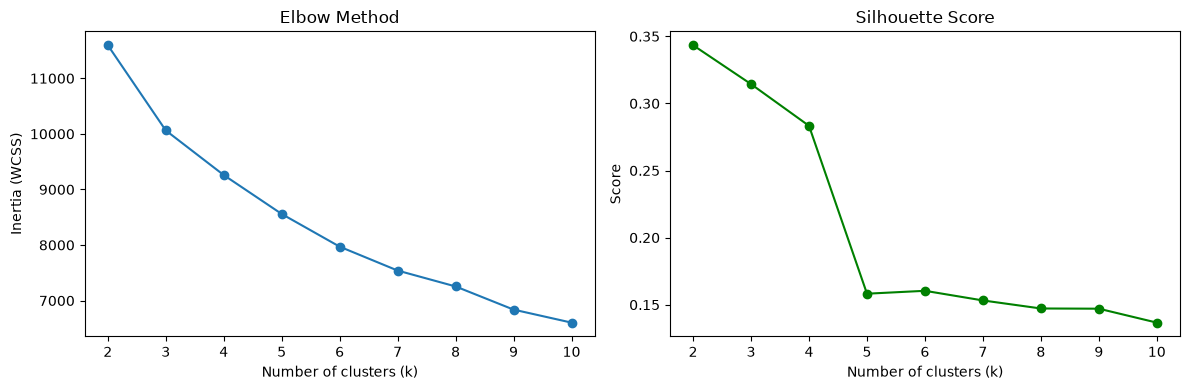

In [5]:
k_range = range(2, 11)
inertias, silhouettes = [], []

for k in k_range:
    km = KMeans(n_clusters=k, init="k-means++", n_init=10, random_state=42)
    labels = km.fit_predict(X_scaled)
    inertias.append(km.inertia_)
    silhouettes.append(silhouette_score(X_scaled, labels))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(k_range, inertias, "o-")
ax[0].set(title="Elbow Method", xlabel="Number of clusters (k)", ylabel="Inertia (WCSS)")
ax[1].plot(k_range, silhouettes, "o-", color="green")
ax[1].set(title="Silhouette Score", xlabel="Number of clusters (k)", ylabel="Score")
plt.tight_layout()
plt.show()

In [6]:
kmeans = KMeans(n_clusters=2, init="k-means++", n_init=10, random_state=42)
clusters = kmeans.fit_predict(X_scaled)

In [7]:
flipped = accuracy_score(y, clusters) < accuracy_score(y, 1 - clusters)
if flipped:
    clusters = 1 - clusters

print("\n--- Evaluation ---")
print(f"Silhouette score:    {silhouette_score(X_scaled, clusters):.3f}")
print(f"Adjusted Rand Index: {adjusted_rand_score(y, clusters):.3f}")
print(f"Accuracy (aligned):  {accuracy_score(y, clusters):.3f}")
print("\nConfusion matrix (rows = true, cols = cluster):")
print(confusion_matrix(y, clusters))


--- Evaluation ---
Silhouette score:    0.343
Adjusted Rand Index: 0.654
Accuracy (aligned):  0.905

Confusion matrix (rows = true, cols = cluster):
[[176  36]
 [ 18 339]]


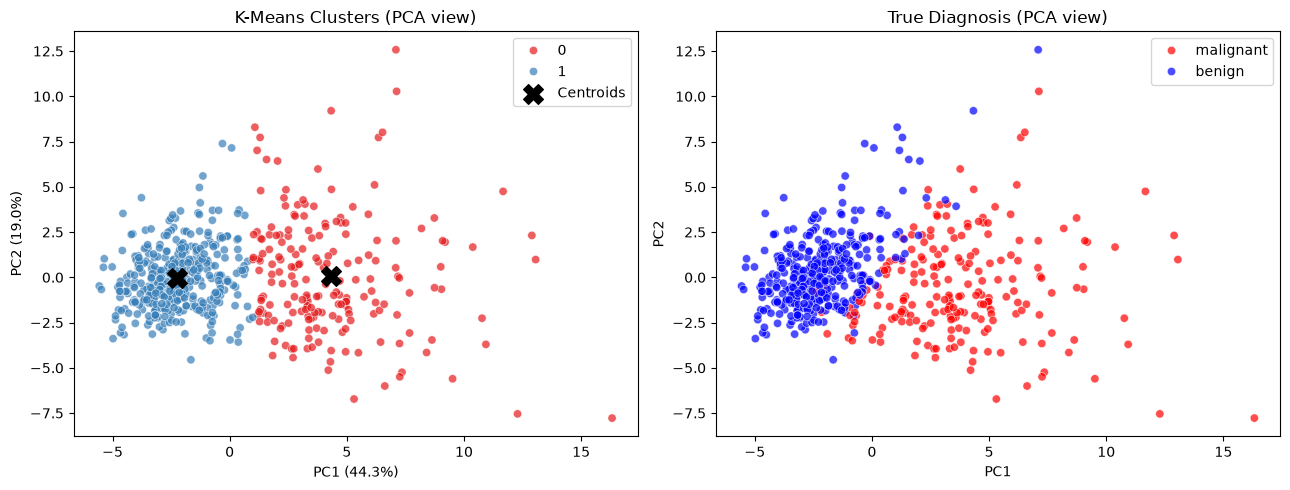

In [8]:
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)
centers_pca = pca.transform(kmeans.cluster_centers_)
if flipped:
    centers_pca = centers_pca[::-1]  # keep centers in the same order as the aligned clusters

fig, ax = plt.subplots(1, 2, figsize=(13, 5))

sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=clusters,
                palette="Set1", alpha=0.7, ax=ax[0])
ax[0].scatter(centers_pca[:, 0], centers_pca[:, 1], c="black",
              marker="X", s=200, label="Centroids")
ax[0].set(title="K-Means Clusters (PCA view)",
          xlabel=f"PC1 ({pca.explained_variance_ratio_[0]:.1%})",
          ylabel=f"PC2 ({pca.explained_variance_ratio_[1]:.1%})")
ax[0].legend()

sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1],
                hue=np.where(y == 0, "malignant", "benign"),
                palette={"malignant": "red", "benign": "blue"},
                alpha=0.7, ax=ax[1])
ax[1].set(title="True Diagnosis (PCA view)", xlabel="PC1", ylabel="PC2")

plt.tight_layout()
plt.show()

In [9]:
profile = X.copy()
profile["cluster"] = clusters
print("\n--- Mean of key features per cluster ---")
print(profile.groupby("cluster")[
    ["mean radius", "mean texture", "mean perimeter", "mean area", "mean concavity"]
].mean().round(2))


--- Mean of key features per cluster ---
         mean radius  mean texture  mean perimeter  mean area  mean concavity
cluster                                                                      
0              17.41         21.28          115.45     979.86            0.18
1              12.43         18.26           79.82     486.77            0.04
